In [5]:
!pip install statsmodels


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


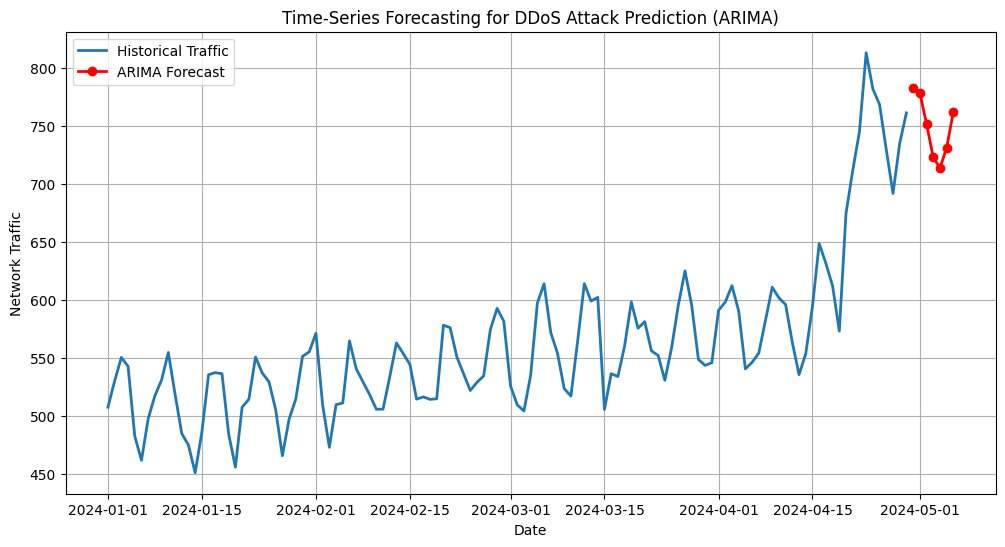

Forecasted Traffic
              Forecast
Date                  
2024-04-30  782.867188
2024-05-01  778.662009
2024-05-02  751.882648
2024-05-03  722.894626
2024-05-04  713.721974
2024-05-05  731.314206
2024-05-06  762.281190

Maximum Forecast Value : 782.87
Threshold              : 620

⚠ Potential DDoS Attack Predicted


In [6]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
import warnings

warnings.filterwarnings("ignore")


np.random.seed(42)

dates = pd.date_range(start="2024-01-01", periods=120, freq="D")

trend = np.linspace(500, 600, 120)

seasonal = 40 * np.sin(np.arange(120) * 2 * np.pi / 7)

noise = np.random.normal(0, 15, 120)

traffic = trend + seasonal + noise



traffic[-10:] += 150



data = pd.DataFrame({
    "Date": dates,
    "Traffic": traffic
})

data.set_index("Date", inplace=True)



model = ARIMA(data["Traffic"], order=(2,1,2))
model_fit = model.fit()



forecast = model_fit.forecast(steps=7)

future_dates = pd.date_range(
    start=data.index[-1] + pd.Timedelta(days=1),
    periods=7,
    freq="D"
)

forecast_df = pd.DataFrame({
    "Date": future_dates,
    "Forecast": forecast.values
})

forecast_df.set_index("Date", inplace=True)



plt.figure(figsize=(12,6))

plt.plot(
    data.index,
    data["Traffic"],
    label="Historical Traffic",
    linewidth=2
)

plt.plot(
    forecast_df.index,
    forecast_df["Forecast"],
    color="red",
    marker="o",
    linewidth=2,
    label="ARIMA Forecast"
)

plt.title("Time-Series Forecasting for DDoS Attack Prediction (ARIMA)")
plt.xlabel("Date")
plt.ylabel("Network Traffic")
plt.legend()
plt.grid(True)

plt.show()



threshold = 620

print("="*50)
print("Forecasted Traffic")
print("="*50)
print(forecast_df)

print("\nMaximum Forecast Value :", round(forecast_df["Forecast"].max(),2))
print("Threshold              :", threshold)

if forecast_df["Forecast"].max() > threshold:
    print("\n⚠ Potential DDoS Attack Predicted")
else:
    print("\n✅ Normal Network Traffic")